In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

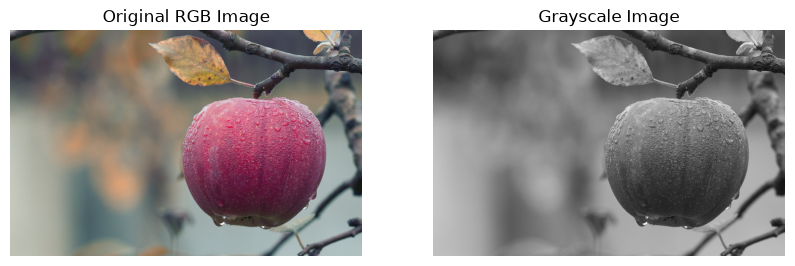

In [3]:


# Load original colour image
img = cv2.imread(r"C:\Users\snaha\Downloads\apple.jpeg")

# Convert BGR to RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert original BGR image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display both images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load original colour image
img = cv2.imread(r"C:\Users\snaha\Downloads\apple.jpeg")

# Convert to RGB for displaying
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [10]:
dark = np.clip(gray.astype(float) - 50, 0, 255).astype(np.uint8)

bright = np.clip(gray.astype(float) + 50, 0, 255).astype(np.uint8)

low_contrast = np.clip(gray.astype(float) * 0.5 + 100, 0, 255).astype(np.uint8)

high_contrast = np.clip((gray.astype(float) - 128) * 2 + 128, 0, 255).astype(np.uint8)

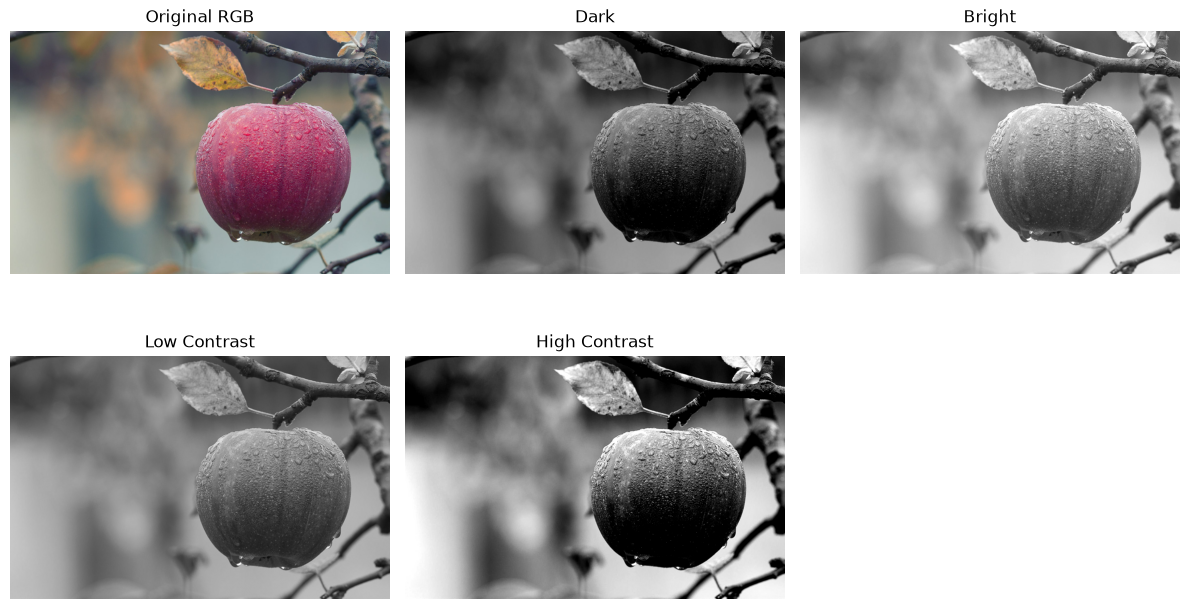

In [11]:
images = [img_rgb, dark, bright, low_contrast, high_contrast]

titles = ["Original RGB", "Dark", "Bright",
          "Low Contrast", "High Contrast"]

plt.figure(figsize=(12, 7))

for i in range(5):
    plt.subplot(2, 3, i+1)

    if i == 0:
        plt.imshow(images[i])
    else:
        plt.imshow(images[i], cmap="gray")

    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

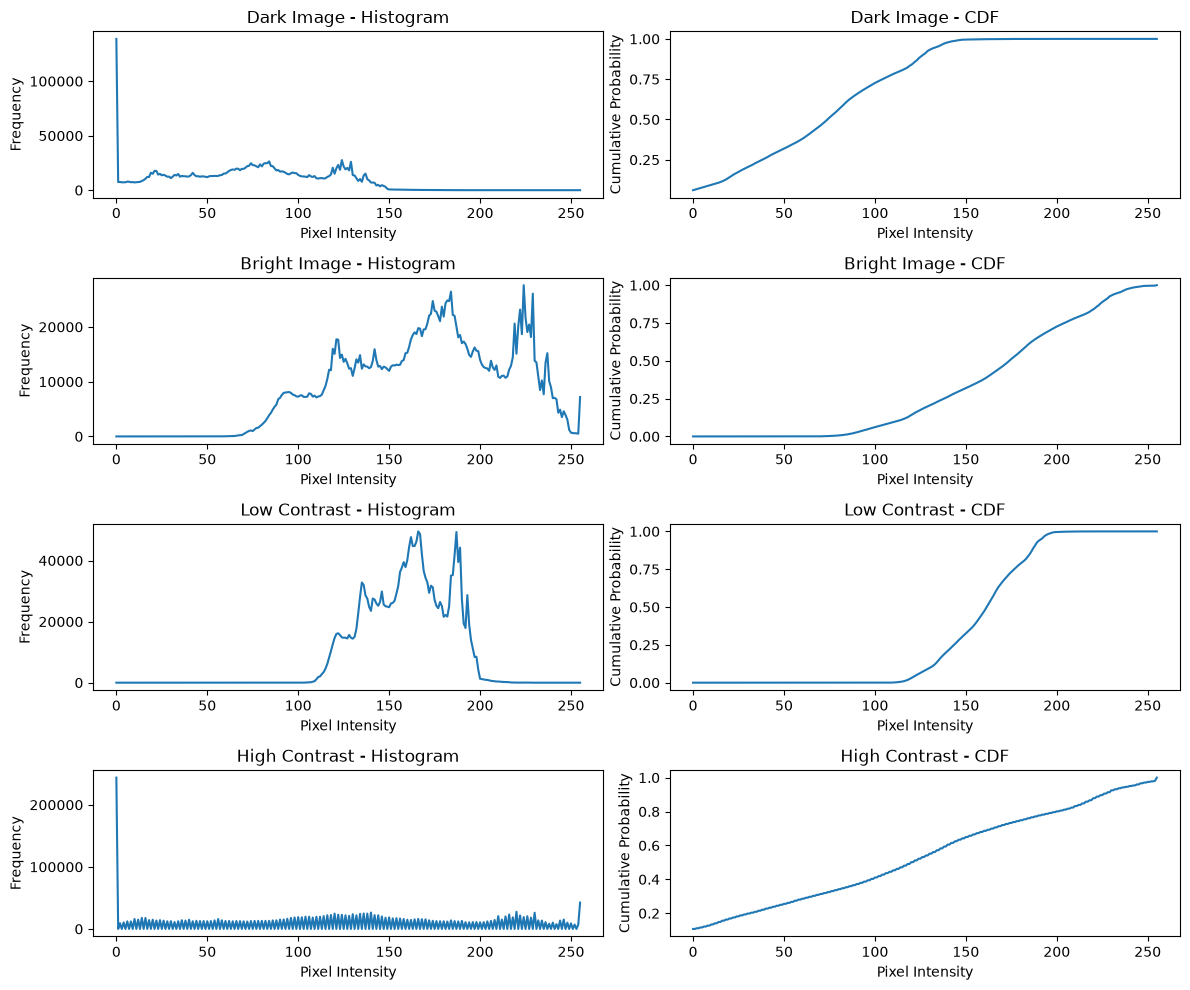

In [12]:
images = [dark, bright, low_contrast, high_contrast]

titles = ["Dark Image", "Bright Image",
          "Low Contrast", "High Contrast"]

plt.figure(figsize=(12, 10))

for i in range(4):

    # Calculate histogram
    hist = cv2.calcHist([images[i]], [0], None, [256], [0, 256])

    # Calculate CDF
    cdf = hist.cumsum()

    # Normalize CDF
    cdf = cdf / cdf.max()

    # Display histogram
    plt.subplot(4, 2, 2*i+1)
    plt.plot(hist)
    plt.title(titles[i] + " - Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

    # Display CDF
    plt.subplot(4, 2, 2*i+2)
    plt.plot(cdf)
    plt.title(titles[i] + " - CDF")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Cumulative Probability")

plt.tight_layout()
plt.show()

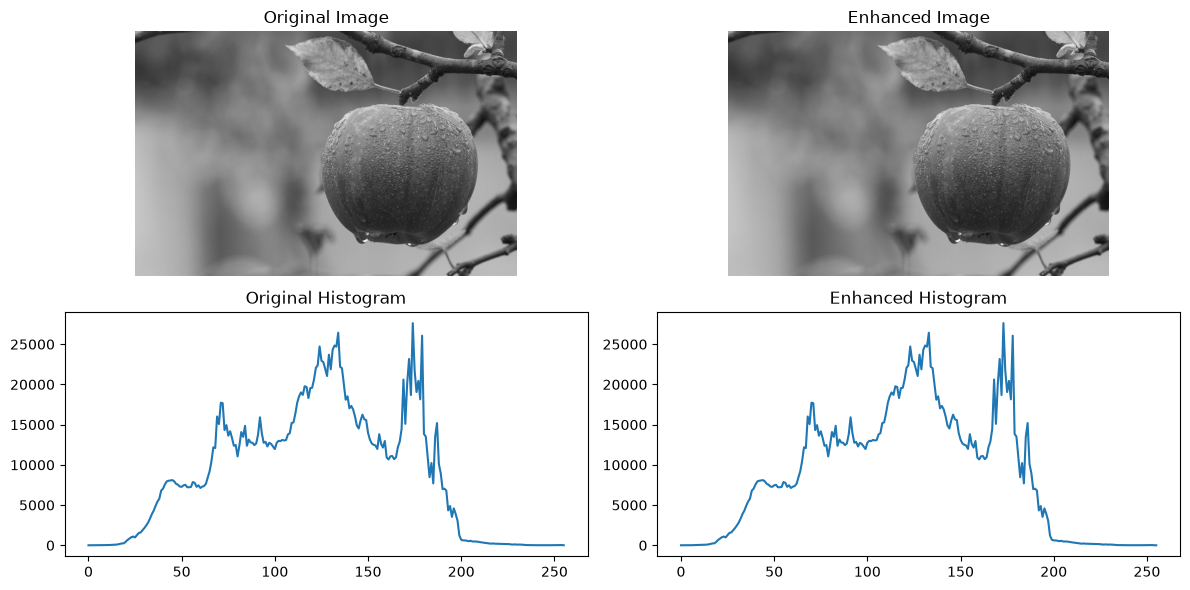

In [13]:
# Find minimum and maximum intensity
r_min = np.min(gray)
r_max = np.max(gray)

# Linear contrast stretching
enhanced = ((gray.astype(float) - r_min) /
            (r_max - r_min) * 255).astype(np.uint8)

# Calculate original histogram
hist_original = cv2.calcHist([gray], [0], None, [256], [0, 256])

# Calculate enhanced histogram
hist_enhanced = cv2.calcHist([enhanced], [0], None, [256], [0, 256])

# Display results
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(enhanced, cmap="gray")
plt.title("Enhanced Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.plot(hist_original)
plt.title("Original Histogram")

plt.subplot(2, 2, 4)
plt.plot(hist_enhanced)
plt.title("Enhanced Histogram")

plt.tight_layout()
plt.show()

In [14]:
print("Original minimum:", np.min(gray))
print("Original maximum:", np.max(gray))

print("Enhanced minimum:", np.min(enhanced))
print("Enhanced maximum:", np.max(enhanced))

print("Original data type:", gray.dtype)
print("Enhanced data type:", enhanced.dtype)

Original minimum: 1
Original maximum: 255
Enhanced minimum: 0
Enhanced maximum: 255
Original data type: uint8
Enhanced data type: uint8
